# Assignment 3 — Edge Computing & Intelligent Systems
**Student:** Ahmed Izaan · **Section:** A  
**Question 1:** Post-training static quantization and quantization-aware training (50 marks)  
**Question 2:** Iterative unstructured and physical structured channel pruning (50 marks)

This notebook contains the complete implementation and **actual executed results**. A single trained, quantization-compatible **ResNet-18** is reused as the original FP32 model in both questions. The five deployment variants are FP32, PTQ-INT8, QAT-INT8, unstructured FP32 and structured FP32.

## How to run
Open this notebook from its extracted folder and choose **Run All**. The source-writing cells create the standalone scripts; later cells train, optimize, export and benchmark them. Internet access is needed only for dependencies and the first CIFAR-10 download. The full dataset is deliberately excluded from the submission archive.

The saved experiment is a modest CPU training run, not a claim of convergence or state-of-the-art accuracy. All 10,000 official test examples are evaluated only after training and model selection. The scripts support longer training by changing the configuration. **No results are fabricated.**

In [1]:
from pathlib import Path
import sys, os
os.environ["ORT_DISABLE_TELEMETRY"] = "1"
ROOT = Path.cwd()
(ROOT / "scripts").mkdir(exist_ok=True)
for folder in ("models", "results", "onnx"):
    (ROOT / folder).mkdir(exist_ok=True)
print("Working folder:", ROOT)
print("Python:", sys.version.split()[0])

Working folder: /workspace/scratch/554aacdf2860/output/Edge_Assignment_3
Python: 3.12.14


## 1. Dependencies and reproducibility
The implementation pins PyTorch 2.5.1 and torchvision 0.20.1 because their eager static quantization and TorchScript export APIs are known and compatible. CPU quantization uses FBGEMM. The native deployment models accept normalized float32 images and return float32 logits; quantization/dequantization boundaries are inside the INT8 models.

If needed, run the following installation commands in a terminal before starting the kernel:
```bash
python -m pip install torch==2.5.1 torchvision==0.20.1 --index-url https://download.pytorch.org/whl/cpu
python -m pip install nbformat nbclient ipykernel pandas matplotlib onnx onnxruntime
```

Determinism is requested with `warn_only=True`: PyTorch 2.5.1 has quantized CPU operations without a strict deterministic implementation. Seeds and thread settings are recorded, but exact cross-machine or cross-backend equality is not guaranteed.

In [2]:
%%writefile scripts/common.py
"""Shared architecture, deterministic CIFAR-10 data, training and deployment utilities."""
import copy, json, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models.quantization import resnet18
from torch.ao.quantization import QuantStub, DeQuantStub

ROOT = Path(__file__).resolve().parents[1]
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
NAMES = ['fp32', 'ptq_int8', 'qat_int8', 'unstructured', 'structured']

def setup(seed=42, threads=4):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if 'fbgemm' not in torch.backends.quantized.supported_engines:
        raise RuntimeError('This experiment requires an x86 CPU build with FBGEMM.')
    torch.backends.quantized.engine = 'fbgemm'
    for d in ('models','results','onnx'):
        (ROOT / d).mkdir(exist_ok=True)

def architecture(hidden_channels=None):
    # Keep the original 7x7/stride-2 stem and max pool: explicit CPU cost tradeoff.
    model = resnet18(weights=None, num_classes=10, quantize=False)
    if hidden_channels:
        for name, width in hidden_channels.items():
            block = model.get_submodule(name)
            old1, old2 = block.conv1, block.conv2
            block.conv1 = nn.Conv2d(old1.in_channels, width, 3,
                                    old1.stride, old1.padding, bias=False)
            block.bn1 = nn.BatchNorm2d(width)
            block.conv2 = nn.Conv2d(width, old2.out_channels, 3,
                                    old2.stride, old2.padding, bias=False)
    return model

def data(config):
    train_tf = transforms.Compose([transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize(MEAN,STD)])
    eval_tf = transforms.Compose([transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
    folder = config['data_dir']
    train_aug = datasets.CIFAR10(folder,train=True,download=True,transform=train_tf)
    train_eval = datasets.CIFAR10(folder,train=True,download=False,transform=eval_tf)
    test = datasets.CIFAR10(folder,train=False,download=True,transform=eval_tf)
    labels = np.asarray(train_aug.targets)
    rng = np.random.default_rng(config['seed'])
    train_ids, val_ids = [], []
    for c in range(10):
        ids = rng.permutation(np.where(labels == c)[0])
        val_ids.extend(ids[:500].tolist()); train_ids.extend(ids[500:].tolist())
    train_ids = rng.permutation(train_ids).tolist()
    val_ids = sorted(val_ids)
    # Balanced calibration subset: only training images, no augmented/random crop.
    calibration_ids = []
    for c in range(10):
        calibration_ids.extend([i for i in train_ids if labels[i] == c][:100])
    kw = dict(batch_size=config['batch_size'],num_workers=0)
    generator = torch.Generator().manual_seed(config['seed'])
    train = DataLoader(Subset(train_aug,train_ids),shuffle=True,generator=generator,**kw)
    val = DataLoader(Subset(train_eval,val_ids),shuffle=False,**kw)
    calibration = DataLoader(Subset(train_eval,calibration_ids),shuffle=False,**kw)
    test_loader = DataLoader(test,shuffle=False,**kw)
    np.savez(ROOT/'results'/'data_split.npz',train=np.array(train_ids),
             validation=np.array(val_ids),calibration=np.array(calibration_ids))
    return train,val,calibration,test_loader

@torch.inference_mode()
def evaluate(model, loader):
    model.eval(); correct = count = 0; loss = 0.0
    for x,y in loader:
        logits=model(x); loss+=nn.functional.cross_entropy(logits,y,reduction='sum').item()
        correct+=(logits.argmax(1)==y).sum().item(); count+=len(y)
    return {'loss':loss/count,'accuracy_pct':100*correct/count,'n':count}

def fit(model, train, val, epochs, lr, tag, qat=False, keep_best=True):
    optimizer=torch.optim.SGD(model.parameters(),lr=lr,momentum=0.9,weight_decay=5e-4)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(epochs,1))
    rows=[]; best=-1; best_state=None
    for epoch in range(epochs):
        start=time.perf_counter(); model.train()
        if qat:
            # Preserve pretrained BN statistics throughout the short QAT fine-tune.
            model.apply(torch.ao.nn.intrinsic.qat.freeze_bn_stats)
        total=correct=0; loss_sum=0
        for step,(x,y) in enumerate(train):
            if qat and epoch==epochs-1 and step==max(1,len(train)//2):
                model.apply(torch.ao.quantization.disable_observer)
            optimizer.zero_grad(set_to_none=True)
            out=model(x); loss=nn.functional.cross_entropy(out,y)
            loss.backward(); optimizer.step()
            total+=len(y); correct+=(out.argmax(1)==y).sum().item(); loss_sum+=loss.item()*len(y)
        metric=evaluate(model,val)
        row=dict(stage=tag,epoch=epoch+1,train_loss=loss_sum/total,
                 train_accuracy_pct=100*correct/total,val_accuracy_pct=metric['accuracy_pct'],
                 seconds=time.perf_counter()-start,learning_rate=optimizer.param_groups[0]['lr'])
        rows.append(row); print(row,flush=True)
        if metric['accuracy_pct']>best:
            best=metric['accuracy_pct']; best_state=copy.deepcopy(model.state_dict())
        scheduler.step()
    if keep_best and best_state is not None: model.load_state_dict(best_state)
    pd.DataFrame(rows).to_csv(ROOT/'results'/f'{tag}_training.csv',index=False)
    return model.eval()

def save_float(model,name,hidden_channels=None):
    torch.save({'state_dict':model.state_dict(),'hidden_channels':hidden_channels or {},
                'architecture':'torchvision quantizable ResNet-18, original stem, 10 classes'},
               ROOT/'models'/f'{name}.pth')
    deploy(model,name)

def load_float(name='fp32'):
    ckpt=torch.load(ROOT/'models'/f'{name}.pth',map_location='cpu',weights_only=True)
    m=architecture(ckpt['hidden_channels']); m.load_state_dict(ckpt['state_dict'])
    return m.eval()

def deploy(model,name):
    # TorchScript file is directly executable without reconstructing a Python class.
    model.eval(); scripted=torch.jit.script(model)
    scripted.save(str(ROOT/'models'/f'{name}.pt'))
    loaded=torch.jit.load(str(ROOT/'models'/f'{name}.pt')).eval()
    x=torch.randn(2,3,32,32)
    with torch.inference_mode():
        torch.testing.assert_close(loaded(x),model(x),rtol=1e-4,atol=1e-5)
    print(f'Saved and reloaded {name}: output shape {tuple(loaded(x).shape)}',flush=True)

def load_config():
    return json.loads((ROOT/'config.json').read_text())


Overwriting scripts/common.py


In [3]:
import sys, json, platform, torch, torchvision, numpy as np, pandas as pd
sys.path.insert(0, str(ROOT / 'scripts'))
from common import *
config = {
    'seed': 42, 'threads': 4, 'batch_size': 128,
    'baseline_epochs': 4, 'qat_epochs': 1, 'finetune_epochs': 1,
    'data_dir': str(ROOT.parent.parent / 'data'),
    'unstructured_amount_per_iteration': 0.20,
    'pruning_iterations': 3, 'channel_prune_fraction': 0.25,
}
(ROOT / 'config.json').write_text(json.dumps(config, indent=2))
setup(config['seed'], config['threads'])
environment = {'python':sys.version, 'pytorch':torch.__version__, 'torchvision':torchvision.__version__,
               'platform':platform.platform(), 'cpu_threads':torch.get_num_threads(),
               'quantization_backend':torch.backends.quantized.engine, 'cuda':torch.cuda.is_available()}
(ROOT / 'results/environment.json').write_text(json.dumps(environment, indent=2))
display(pd.DataFrame(environment.items(), columns=['Setting','Value']))
train_loader, val_loader, calibration_loader, test_loader = data(config)
display(pd.DataFrame({'Split':['Training','Validation','Calibration (within training)','Official test'],
                      'Images':[len(train_loader.dataset),len(val_loader.dataset),
                                len(calibration_loader.dataset),len(test_loader.dataset)]}))

Using downloaded and verified file: /workspace/scratch/554aacdf2860/data/cifar-10-python.tar.gz
Extracting /workspace/scratch/554aacdf2860/data/cifar-10-python.tar.gz to /workspace/scratch/554aacdf2860/data
Files already downloaded and verified


,Setting,Value
0,python,"3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 2..."
1,pytorch,2.5.1+cpu
2,torchvision,0.20.1+cpu
3,platform,Linux-6.18.57-x86_64-with-glibc2.41
4,cpu_threads,4
5,quantization_backend,fbgemm
6,cuda,False


,Split,Images
0,Training,45000
1,Validation,5000
2,Calibration (within training),1000
3,Official test,10000


# Question 1 — FP32, PTQ and QAT
## 2. Train and save the baseline ResNet-18
The classifier has 10 output classes. Random crop and horizontal flip are applied only to training. A stratified **45,000 / 5,000** training/validation split is fixed by the seed. Validation selects the best epoch; test images never influence calibration, channel selection or model selection.

The original ResNet-18 7×7 stride-2 stem and max-pool are retained to make this run feasible on CPU. For stronger CIFAR-10 accuracy, a 3×3 stride-1 stem without max-pool and more epochs would normally be preferable, but that is a different experiment. This choice is recorded explicitly instead of silently presenting an undertrained model as converged.

In [4]:
%%writefile scripts/train_baseline.py
"""Train FP32 ResNet-18 on CIFAR-10 and export its checkpoints."""
from common import *

def run(config,loaders=None):
    setup(config['seed'],config['threads'])
    train,val,_,_=loaders or data(config)
    model=architecture()
    print('Trainable baseline parameters:',sum(p.numel() for p in model.parameters()),flush=True)
    fit(model,train,val,config['baseline_epochs'],0.05,'baseline')
    save_float(model,'fp32')
    return model

if __name__=='__main__': run(load_config())


Overwriting scripts/train_baseline.py


In [5]:
from train_baseline import run as train_baseline
loaders = (train_loader, val_loader, calibration_loader, test_loader)
fp32_model = train_baseline(config, loaders)
display(pd.read_csv(ROOT / 'results/baseline_training.csv'))

Trainable baseline parameters: 11181642
{'stage': 'baseline', 'epoch': 1, 'train_loss': 1.961834227074517, 'train_accuracy_pct': 33.59111111111111, 'val_accuracy_pct': 38.54, 'seconds': 63.24683450400005, 'learning_rate': 0.05}
{'stage': 'baseline', 'epoch': 2, 'train_loss': 1.5316912170834012, 'train_accuracy_pct': 45.306666666666665, 'val_accuracy_pct': 49.3, 'seconds': 61.06045372599999, 'learning_rate': 0.04267766952966369}
{'stage': 'baseline', 'epoch': 3, 'train_loss': 1.2710280692630345, 'train_accuracy_pct': 54.21333333333333, 'val_accuracy_pct': 59.24, 'seconds': 60.59587676299998, 'learning_rate': 0.025}
{'stage': 'baseline', 'epoch': 4, 'train_loss': 1.0968057793723212, 'train_accuracy_pct': 60.602222222222224, 'val_accuracy_pct': 62.18, 'seconds': 59.47025306600017, 'learning_rate': 0.0073223304703363135}
Saved and reloaded fp32: output shape (2, 10)


,stage,epoch,train_loss,train_accuracy_pct,val_accuracy_pct,seconds,learning_rate
0,baseline,1,1.961834,33.591111,38.54,63.246835,0.050000
1,baseline,2,1.531691,45.306667,49.30,61.060454,0.042678
2,baseline,3,1.271028,54.213333,59.24,60.595877,0.025000
3,baseline,4,1.096806,60.602222,62.18,59.470253,0.007322


## 3. Post-training static quantization (PTQ)
1. Load the pretrained FP32 checkpoint and set evaluation mode.
2. Fuse compatible convolution/BN/ReLU groups, including residual downsample branches.
3. Set FBGEMM's default static quantization configuration and insert observers with `prepare`.
4. Calibrate on **1,000 balanced, unaugmented training images**.
5. Convert observed operations to integer kernels and export a directly executable checkpoint.

Per-channel weight quantization handles different channel ranges. Activation observers estimate quantization scales from calibration images. Quantization stubs surround the network; residual additions use torchvision's quantizable `FloatFunctional` implementation.

In [6]:
%%writefile scripts/ptq.py
"""Static PTQ: fusion -> observers -> training-only calibration -> INT8 conversion."""
from common import *
from torch.ao.quantization import prepare, convert, get_default_qconfig

def calibrate(model,loader):
    model.eval(); seen=0
    with torch.inference_mode():
        for x,_ in loader: model(x); seen+=len(x)
    return seen

def run(config,loaders=None):
    setup(config['seed'],config['threads'])
    _,_,calibration,_=loaders or data(config)
    model=load_float(); model.fuse_model(is_qat=False)
    model.qconfig=get_default_qconfig('fbgemm')
    prepare(model,inplace=True)
    seen=calibrate(model,calibration)
    print('PTQ calibration images:',seen,flush=True)
    model=convert(model.eval(),inplace=False)
    deploy(model,'ptq_int8')
    return model

if __name__=='__main__': run(load_config())


Overwriting scripts/ptq.py


In [7]:
%%writefile scripts/calibrate.py
"""Standalone PTQ calibration and conversion entry point."""
from common import load_config
from ptq import run
if __name__=='__main__': run(load_config())


Overwriting scripts/calibrate.py


In [8]:
from ptq import run as run_ptq
ptq_model = run_ptq(config, loaders)
print('Converted first convolution:', ptq_model.conv1)
print('Quantized classifier weight dtype:', ptq_model.fc.weight().dtype)

PTQ calibration images: 1000
Saved and reloaded ptq_int8: output shape (2, 10)
Converted first convolution: QuantizedConvReLU2d(3, 64, kernel_size=(7, 7), stride=(2, 2), scale=0.06464597582817078, zero_point=0, padding=(3, 3))
Quantized classifier weight dtype: torch.qint8


/home/agent/.local/lib/python3.12/site-packages/torch/ao/quantization/observer.py:229: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  warnings.warn(
/home/agent/.local/lib/python3.12/site-packages/torch/nn/modules/module.py:1747: UserWarning: quantized_resize_cpu_ does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at ../aten/src/ATen/Context.cpp:91.)
  return forward_call(*args, **kwargs)


## 4. Quantization-aware training (QAT)
QAT starts from the **same trained FP32 checkpoint**, uses QAT-compatible fusion and `prepare_qat` to insert fake quantizers. Weights remain floating point during training, while fake quantizers simulate the rounding and clipping of INT8 inference. The straight-through estimator supplies approximate gradients through rounding.

Fine-tuning uses a smaller learning rate. Pretrained batch-normalization statistics are frozen, and observers stop updating halfway through the final epoch. `convert` produces the final true INT8 model; fake quantizers are not deployment kernels.

In [9]:
%%writefile scripts/qat.py
"""QAT from the pretrained baseline, followed by real INT8 conversion."""
from common import *
from torch.ao.quantization import prepare_qat,convert,get_default_qat_qconfig,FakeQuantizeBase

def run(config,loaders=None):
    setup(config['seed'],config['threads'])
    train,val,_,_=loaders or data(config)
    model=load_float().train(); model.fuse_model(is_qat=True)
    model.qconfig=get_default_qat_qconfig('fbgemm')
    prepare_qat(model,inplace=True)
    print('Inserted fake quantization modules:',sum(isinstance(m,FakeQuantizeBase) for m in model.modules()),flush=True)
    fit(model,train,val,config['qat_epochs'],0.001,'qat',qat=True,keep_best=False)
    model=convert(model.eval(),inplace=False)
    deploy(model,'qat_int8')
    return model

if __name__=='__main__': run(load_config())


Overwriting scripts/qat.py


In [10]:
from qat import run as run_qat
qat_model = run_qat(config, loaders)
display(pd.read_csv(ROOT / 'results/qat_training.csv'))

Inserted fake quantization modules: 51
{'stage': 'qat', 'epoch': 1, 'train_loss': 1.0210558562172785, 'train_accuracy_pct': 63.46666666666667, 'val_accuracy_pct': 64.72, 'seconds': 85.565512808, 'learning_rate': 0.001}
Saved and reloaded qat_int8: output shape (2, 10)


,stage,epoch,train_loss,train_accuracy_pct,val_accuracy_pct,seconds,learning_rate
0,qat,1,1.021056,63.466667,64.72,85.565513,0.001


# Question 2 — Neural network pruning
## 5. Iterative magnitude-based unstructured pruning
All convolution and fully connected weights are included in **global L1 magnitude pruning**. Three iterations each remove 20% of the currently surviving weights:
\[
s_k = 1-(1-0.20)^k,
\]
so the final target sparsity is approximately **48.8%** (small integer rounding differences are expected).

Masks remain attached during all recovery training, preventing removed weights from regrowing. Each iteration receives a short 5,000-image training-only recovery pass; a final full-training-set fine-tune follows. Then `prune.remove` folds each mask into the stored weights. An optional gzip checkpoint demonstrates storage compression; dense convolution kernels still process zero entries, so unstructured sparsity is **not automatically a runtime speedup**.

In [11]:
%%writefile scripts/prune_unstructured.py
"""Iterative global magnitude pruning with masks preserved until fine-tuning ends."""
import gzip, shutil
from torch.nn.utils import prune
from common import *

def weight_modules(model):
    return [(m,'weight') for m in model.modules() if isinstance(m,(nn.Conv2d,nn.Linear))]

def sparsity(model):
    modules=weight_modules(model)
    zero=sum((m.weight.detach()==0).sum().item() for m,_ in modules)
    total=sum(m.weight.numel() for m,_ in modules)
    return zero,total,100*zero/total

def run(config,loaders=None):
    setup(config['seed'],config['threads'])
    train,val,_,_=loaders or data(config)
    model=load_float(); params=weight_modules(model); rows=[]
    # A deterministic training-only recovery subset; no test examples.
    short=DataLoader(Subset(train.dataset,list(range(5000))),batch_size=config['batch_size'],shuffle=True)
    for iteration in range(config['pruning_iterations']):
        prune.global_unstructured(params,pruning_method=prune.L1Unstructured,
                                  amount=config['unstructured_amount_per_iteration'])
        z,n,s=sparsity(model)
        print(f'Iteration {iteration+1}: {z:,}/{n:,} weights zero ({s:.3f}%)',flush=True)
        fit(model,short,val,1,0.002,f'unstructured_iteration_{iteration+1}',keep_best=False)
        rows.append(dict(iteration=iteration+1,zero_weights=z,total_weights=n,sparsity_pct=s,
                         val_accuracy_pct=evaluate(model,val)['accuracy_pct']))
    fit(model,train,val,config['finetune_epochs'],0.001,'unstructured_final',keep_best=False)
    for module,name in params: prune.remove(module,name)
    assert not any('weight_mask' in key or 'weight_orig' in key for key in model.state_dict())
    assert abs(sparsity(model)[2]-100*(1-0.8**config['pruning_iterations']))<0.01
    pd.DataFrame(rows).to_csv(ROOT/'results'/'pruning_iterations.csv',index=False)
    save_float(model,'unstructured')
    src=ROOT/'models'/'unstructured.pth'
    with src.open('rb') as f, gzip.open(str(src)+'.gz','wb',compresslevel=9) as out:
        shutil.copyfileobj(f,out)
    print('Permanent masks removed; remaining zeros:',sparsity(model),flush=True)
    return model

if __name__=='__main__': run(load_config())


Overwriting scripts/prune_unstructured.py


In [12]:
from prune_unstructured import run as run_unstructured
unstructured_model = run_unstructured(config, loaders)
display(pd.read_csv(ROOT / 'results/pruning_iterations.csv'))

Iteration 1: 2,234,406/11,172,032 weights zero (20.000%)
{'stage': 'unstructured_iteration_1', 'epoch': 1, 'train_loss': 1.0453489276885986, 'train_accuracy_pct': 62.76, 'val_accuracy_pct': 61.34, 'seconds': 8.135319631999891, 'learning_rate': 0.002}
Iteration 2: 4,021,931/11,172,032 weights zero (36.000%)
{'stage': 'unstructured_iteration_2', 'epoch': 1, 'train_loss': 1.0441148122787476, 'train_accuracy_pct': 62.5, 'val_accuracy_pct': 64.06, 'seconds': 8.495584462000124, 'learning_rate': 0.002}
Iteration 3: 5,451,951/11,172,032 weights zero (48.800%)
{'stage': 'unstructured_iteration_3', 'epoch': 1, 'train_loss': 1.0132014015197754, 'train_accuracy_pct': 64.32, 'val_accuracy_pct': 64.64, 'seconds': 8.553794288000063, 'learning_rate': 0.002}
{'stage': 'unstructured_final', 'epoch': 1, 'train_loss': 1.0208954893430073, 'train_accuracy_pct': 63.58222222222222, 'val_accuracy_pct': 65.52, 'seconds': 57.65283473399995, 'learning_rate': 0.001}
Saved and reloaded unstructured: output shape (2

,iteration,zero_weights,total_weights,sparsity_pct,val_accuracy_pct
0,1,2234406,11172032,19.999996,61.34
1,2,4021931,11172032,35.999995,64.06
2,3,5451951,11172032,48.799994,64.64


## 6. Structured channel pruning with physical reconstruction
For every ResNet BasicBlock, rank `conv1` output channels by mean absolute filter weight. Keep the strongest **75%** and physically create:

- `conv1`: fewer output channels;
- `bn1`: the matching reduced normalization parameters and running statistics;
- `conv2`: matching fewer input channels.

The block's external input/output widths, projection branch and residual addition remain unchanged. This dependency-aware choice prunes internal channels without invalidating the skip connection. The model **has smaller tensors and fewer parameters**, rather than merely zero-masked channels. It is fine-tuned on the full training split. This is a valid restricted channel-pruning strategy, not pruning of every stage's external width.

In [13]:
%%writefile scripts/prune_structured.py
"""Physical dependency-aware channel removal inside all eight ResNet-18 BasicBlocks."""
from common import *

def reconstruct(original,fraction):
    model=copy.deepcopy(original).eval(); hidden={}; rows=[]
    for name,block in list(model.named_modules()):
        if not (name.startswith('layer') and name.count('.')==1): continue
        conv1,bn1,conv2=block.conv1,block.bn1,block.conv2
        score=conv1.weight.detach().abs().mean(dim=(1,2,3))
        keep_count=max(1,round(conv1.out_channels*(1-fraction)))
        keep=score.topk(keep_count).indices.sort().values
        new1=nn.Conv2d(conv1.in_channels,keep_count,3,conv1.stride,conv1.padding,bias=False)
        new_bn=nn.BatchNorm2d(keep_count,eps=bn1.eps,momentum=bn1.momentum)
        new2=nn.Conv2d(keep_count,conv2.out_channels,3,conv2.stride,conv2.padding,bias=False)
        with torch.no_grad():
            new1.weight.copy_(conv1.weight[keep])
            new2.weight.copy_(conv2.weight[:,keep])
            for attr in ('weight','bias','running_mean','running_var'):
                getattr(new_bn,attr).copy_(getattr(bn1,attr)[keep])
            new_bn.num_batches_tracked.copy_(bn1.num_batches_tracked)
        block.conv1,block.bn1,block.conv2=new1,new_bn,new2
        hidden[name]=keep_count
        rows.append(dict(block=name,original_hidden=conv1.out_channels,kept_hidden=keep_count,
                         removed_hidden=conv1.out_channels-keep_count))
    model.eval()
    with torch.inference_mode(): assert model(torch.randn(2,3,32,32)).shape==(2,10)
    assert all('mask' not in k for k in model.state_dict())
    return model,hidden,rows

def run(config,loaders=None):
    setup(config['seed'],config['threads'])
    train,val,_,_=loaders or data(config)
    original=load_float(); model,hidden,rows=reconstruct(original,config['channel_prune_fraction'])
    before=sum(p.numel() for p in original.parameters()); after=sum(p.numel() for p in model.parameters())
    assert after<before
    print(f'Physical parameters: {before:,} -> {after:,} ({100*(1-after/before):.2f}% fewer)',flush=True)
    pre=evaluate(model,val)['accuracy_pct']
    fit(model,train,val,config['finetune_epochs'],0.002,'structured',keep_best=True)
    post=evaluate(model,val)['accuracy_pct']
    print(f'Structured validation accuracy before/after fine-tuning: {pre:.2f}% / {post:.2f}%',flush=True)
    pd.DataFrame(rows).to_csv(ROOT/'results'/'structured_channels.csv',index=False)
    (ROOT/'results'/'structured_recovery.json').write_text(json.dumps({'before_val_accuracy_pct':pre,
        'after_val_accuracy_pct':post,'parameters_before':before,'parameters_after':after},indent=2))
    save_float(model,'structured',hidden)
    # Verify architecture reconstruction from checkpoint metadata, not only TorchScript.
    restored=load_float('structured')
    with torch.inference_mode():
        x=torch.randn(2,3,32,32); torch.testing.assert_close(restored(x),model(x))
    return model

if __name__=='__main__': run(load_config())


Overwriting scripts/prune_structured.py


In [14]:
from prune_structured import run as run_structured
structured_model = run_structured(config, loaders)
display(pd.read_csv(ROOT / 'results/structured_channels.csv'))

Physical parameters: 11,181,642 -> 8,434,314 (24.57% fewer)
{'stage': 'structured', 'epoch': 1, 'train_loss': 1.051723544608222, 'train_accuracy_pct': 62.21111111111111, 'val_accuracy_pct': 64.52, 'seconds': 46.56317432300011, 'learning_rate': 0.002}
Structured validation accuracy before/after fine-tuning: 52.42% / 64.52%
Saved and reloaded structured: output shape (2, 10)


,block,original_hidden,kept_hidden,removed_hidden
0,layer1.0,64,48,16
1,layer1.1,64,48,16
2,layer2.0,128,96,32
3,layer2.1,128,96,32
4,layer3.0,256,192,64
5,layer3.1,256,192,64
6,layer4.0,512,384,128
7,layer4.1,512,384,128


## 7. A unified deployment inference pipeline
Each `.pt` checkpoint is independently loadable with `torch.jit.load`. The inference script supports all five variants, either a supplied image (converted to RGB and resized to 32×32) or a CIFAR-10 test image. Labels use CIFAR-10's original class order. The CLI reports the predicted class and softmax score; the score is not a calibrated probability of correctness.

In [15]:
%%writefile scripts/inference.py
"""CPU inference for all five native deployment models."""
import argparse
from PIL import Image
from common import *

def predict(name,image=None,index=0):
    setup(); model=torch.jit.load(str(ROOT/'models'/f'{name}.pt'),map_location='cpu').eval()
    transform=transforms.Compose([transforms.Resize((32,32)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
    if image: x=transform(Image.open(image).convert('RGB')).unsqueeze(0)
    else:
        ds=datasets.CIFAR10(load_config()['data_dir'],train=False,download=True,transform=transform)
        x=ds[index][0].unsqueeze(0)
    with torch.inference_mode(): score=model(x).softmax(1)[0]
    i=int(score.argmax()); return {'model':name,'class_index':i,'class_name':CLASSES[i],'softmax_score':float(score[i])}

if __name__=='__main__':
    parser=argparse.ArgumentParser(); parser.add_argument('--model',choices=NAMES,default='fp32')
    parser.add_argument('--image'); parser.add_argument('--index',type=int,default=0)
    args=parser.parse_args(); print(json.dumps(predict(args.model,args.image,args.index),indent=2))


Overwriting scripts/inference.py


In [16]:
from inference import predict
display(pd.DataFrame([predict(name, index=0) for name in NAMES]))

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


/home/agent/.local/lib/python3.12/site-packages/torch/nn/modules/module.py:1747: UserWarning: quantized_resize_cpu_ does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at ../aten/src/ATen/Context.cpp:91.)
  return forward_call(*args, **kwargs)


,model,class_index,class_name,softmax_score
0,fp32,5,dog,0.503141
1,ptq_int8,5,dog,0.470282
2,qat_int8,3,cat,0.502717
3,unstructured,3,cat,0.467592
4,structured,3,cat,0.480020


## 8. Automated benchmarking and per-image predictions
Every model is reloaded from disk and evaluated on **all 10,000 official test images**. Two CSVs separate concerns:

- `benchmark.csv`: accuracy, executable checkpoint size, warm single-image p50/p95/p99 latency, and batch throughput;
- `test_predictions.csv`: one row per model per test image, with true/predicted labels, correctness, softmax score and the measured batch inference time.

Inference timing excludes preprocessing, dataset loading, disk I/O and model loading. Warm-up uses synthetic inputs. Latency measures **100 batch-size-1 forward passes**; throughput is total test examples divided by total measured batch forward time. All variants use the same CPU thread count. A per-row batch time divided by its size is an **amortized** measurement, not independently measured image latency. Small timing differences should not be overinterpreted.

In [17]:
%%writefile scripts/benchmark.py
"""Reload all checkpoints; measure full-test accuracy, predictions, warm latency and throughput."""
from common import *

@torch.inference_mode()
def run(config,loader=None):
    setup(config['seed'],config['threads'])
    if loader is None: loader=data(config)[3]
    summary=[]; predictions=[]
    for name in NAMES:
        model=torch.jit.load(str(ROOT/'models'/f'{name}.pt'),map_location='cpu').eval()
        probe=torch.randn(1,3,32,32)
        for _ in range(20): model(probe)
        latency=[]
        for _ in range(100):
            start=time.perf_counter_ns(); model(probe)
            latency.append((time.perf_counter_ns()-start)/1e6)
        correct=total=0; inference_seconds=0.0
        for batch_index,(x,y) in enumerate(loader):
            start=time.perf_counter_ns(); logits=model(x)
            elapsed_ms=(time.perf_counter_ns()-start)/1e6
            inference_seconds+=elapsed_ms/1000
            probabilities=logits.softmax(1); confidence,pred=probabilities.max(1)
            for j in range(len(y)):
                predictions.append(dict(model=name,test_index=total+j,true_label=int(y[j]),
                    predicted_label=int(pred[j]),true_class=CLASSES[int(y[j])],predicted_class=CLASSES[int(pred[j])],
                    correct=bool(pred[j]==y[j]),softmax_score=float(confidence[j]),batch_index=batch_index,
                    batch_size=len(y),batch_inference_ms=elapsed_ms,amortized_ms_per_image=elapsed_ms/len(y)))
            correct+=(pred==y).sum().item(); total+=len(y)
        row=dict(model=name,test_images=total,accuracy_pct=100*correct/total,
                 checkpoint_mib=(ROOT/'models'/f'{name}.pt').stat().st_size/2**20,
                 latency_p50_ms=float(np.percentile(latency,50)),latency_p95_ms=float(np.percentile(latency,95)),
                 latency_p99_ms=float(np.percentile(latency,99)),throughput_images_s=total/inference_seconds,
                 inference_only_seconds=inference_seconds,threads=config['threads'])
        summary.append(row); print(row,flush=True)
    frame=pd.DataFrame(summary); pred_frame=pd.DataFrame(predictions)
    assert len(pred_frame)==5*len(loader.dataset)
    assert pred_frame.groupby('model').test_index.nunique().eq(len(loader.dataset)).all()
    frame.to_csv(ROOT/'results'/'benchmark.csv',index=False)
    pred_frame.to_csv(ROOT/'results'/'test_predictions.csv',index=False)
    frame.iloc[:3].to_csv(ROOT/'results'/'question1_benchmark.csv',index=False)
    frame[frame.model.isin(['fp32','unstructured','structured'])].to_csv(ROOT/'results'/'question2_benchmark.csv',index=False)
    return frame,pred_frame

if __name__=='__main__': run(load_config())


Overwriting scripts/benchmark.py


In [18]:
from benchmark import run as run_benchmark
benchmark_results, predictions = run_benchmark(config, test_loader)
display(benchmark_results.round(3))
display(predictions.head(10))
print('Prediction rows:', len(predictions))

{'model': 'fp32', 'test_images': 10000, 'accuracy_pct': 62.41, 'checkpoint_mib': 42.77388000488281, 'latency_p50_ms': 6.3302499999999995, 'latency_p95_ms': 8.8787556, 'latency_p99_ms': 9.719815210000014, 'throughput_images_s': 3316.486805251781, 'inference_only_seconds': 3.015238892, 'threads': 4}
{'model': 'ptq_int8', 'test_images': 10000, 'accuracy_pct': 61.7, 'checkpoint_mib': 10.796955108642578, 'latency_p50_ms': 0.2613935, 'latency_p95_ms': 0.42647624999999995, 'latency_p99_ms': 0.5056719500000012, 'throughput_images_s': 11253.058276000209, 'inference_only_seconds': 0.8886473130000002, 'threads': 4}
{'model': 'qat_int8', 'test_images': 10000, 'accuracy_pct': 64.56, 'checkpoint_mib': 10.796955108642578, 'latency_p50_ms': 0.4145415, 'latency_p95_ms': 0.46456545, 'latency_p99_ms': 0.6107915100000042, 'throughput_images_s': 11584.936883224911, 'inference_only_seconds': 0.863189856, 'threads': 4}
{'model': 'unstructured', 'test_images': 10000, 'accuracy_pct': 65.14, 'checkpoint_mib': 4

/home/agent/.local/lib/python3.12/site-packages/torch/nn/modules/module.py:1747: UserWarning: quantized_resize_cpu_ does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at ../aten/src/ATen/Context.cpp:91.)
  return forward_call(*args, **kwargs)


,model,test_images,accuracy_pct,checkpoint_mib,latency_p50_ms,latency_p95_ms,latency_p99_ms,throughput_images_s,inference_only_seconds,threads
0,fp32,10000,62.41,42.774,6.330,8.879,9.720,3316.487,3.015,4
1,ptq_int8,10000,61.70,10.797,0.261,0.426,0.506,11253.058,0.889,4
2,qat_int8,10000,64.56,10.797,0.415,0.465,0.611,11584.937,0.863,4
3,unstructured,10000,65.14,42.783,5.679,6.854,7.617,3761.493,2.659,4
4,structured,10000,64.05,32.316,4.327,5.000,6.599,4595.007,2.176,4


,model,test_index,true_label,predicted_label,true_class,predicted_class,correct,softmax_score,batch_index,batch_size,batch_inference_ms,amortized_ms_per_image
0,fp32,0,3,5,cat,dog,False,0.503141,0,128,52.054346,0.406675
1,fp32,1,8,8,ship,ship,True,0.731824,0,128,52.054346,0.406675
2,fp32,2,8,8,ship,ship,True,0.867314,0,128,52.054346,0.406675
3,fp32,3,0,0,airplane,airplane,True,0.583796,0,128,52.054346,0.406675
4,fp32,4,6,6,frog,frog,True,0.786082,0,128,52.054346,0.406675
5,fp32,5,6,6,frog,frog,True,0.547640,0,128,52.054346,0.406675
6,fp32,6,1,1,automobile,automobile,True,0.417332,0,128,52.054346,0.406675
7,fp32,7,6,6,frog,frog,True,0.496111,0,128,52.054346,0.406675
8,fp32,8,3,5,cat,dog,False,0.457747,0,128,52.054346,0.406675
9,fp32,9,1,1,automobile,automobile,True,0.892337,0,128,52.054346,0.406675


## 9. ONNX deployment and CPU verification
Export the **same five deployed models**, validate ONNX graphs with `onnx.checker`, and execute them with ONNX Runtime's CPU provider. For native INT8 exports, ONNX uses quantize/dequantize (Q/DQ) representations with integer weight storage; CPU kernel fusion depends on ONNX Runtime. The validation compares logits on 32 test images, reports errors in the final output quantization step, and evaluates ONNX accuracy and native/ONNX prediction agreement on **all 10,000 test images**. Backend rounding can accumulate across quantized layers and change predictions; the measured agreement is reported explicitly, without claiming exact equivalence. A maximum difference of three final output quantization steps is checked for INT8; FP32 exports use a 0.001 absolute tolerance.

No ONNX file is silently substituted with an FP32 baseline. Export failures raise an error and must be resolved before delivery.

Optional ONNX Runtime telemetry is explicitly disabled before creating inference sessions.

In [19]:
%%writefile scripts/export_onnx.py
"""Export each deployed model to ONNX; validate structure and CPU numerical agreement."""
import onnx
import os
os.environ["ORT_DISABLE_TELEMETRY"] = "1"
import onnxruntime as ort
ort.disable_telemetry_events()  # Disable optional runtime telemetry before sessions are created.
from common import *

def run(config,loader=None):
    setup(config['seed'],config['threads'])
    if loader is None: loader=data(config)[3]
    x=next(iter(loader))[0][:32]; rows=[]
    for name in NAMES:
        model=torch.jit.load(str(ROOT/'models'/f'{name}.pt'),map_location='cpu').eval()
        path=ROOT/'onnx'/f'{name}.onnx'
        torch.onnx.export(model,x[:1],str(path),opset_version=17,
            input_names=['images'],output_names=['logits'],
            dynamic_axes={'images':{0:'batch'},'logits':{0:'batch'}},do_constant_folding=True)
        graph=onnx.load(str(path)); onnx.checker.check_model(graph)
        opts=ort.SessionOptions(); opts.intra_op_num_threads=config['threads']; opts.inter_op_num_threads=1
        sess=ort.InferenceSession(str(path),sess_options=opts,providers=['CPUExecutionProvider'])
        with torch.inference_mode(): expected=model(x).numpy()
        actual=sess.run(['logits'],{'images':x.numpy()})[0]
        error=float(np.max(np.abs(expected-actual)))
        agreement=float(np.mean(expected.argmax(1)==actual.argmax(1))*100)
        # Backend rounding can accumulate across layers; audit in final output steps.
        # Also measure full-test deployment accuracy and agreement below.
        output_step=float(model.fc.scale) if 'int8' in name else 0.0
        tolerance=3*output_step+1e-6 if 'int8' in name else 1e-3
        assert error<tolerance,(name,error)
        qnodes=sum(n.op_type=='QuantizeLinear' for n in graph.graph.node)
        if 'int8' in name: assert qnodes>0
        native_correct=onnx_correct=agree=total=0
        for batch,labels in loader:
            actual_logits=sess.run(['logits'],{'images':batch.numpy()})[0]
            with torch.inference_mode(): native_logits=model(batch).numpy()
            actual_pred=actual_logits.argmax(1); native_pred=native_logits.argmax(1)
            onnx_correct+=int((actual_pred==labels.numpy()).sum())
            native_correct+=int((native_pred==labels.numpy()).sum())
            agree+=int((actual_pred==native_pred).sum()); total+=len(labels)
        rows.append(dict(model=name,onnx_mib=path.stat().st_size/2**20,
            checked_images=len(x),max_absolute_logit_error=error,prediction_agreement_pct=agreement,
            quantize_nodes=qnodes,output_quantization_step=output_step,
            max_error_in_output_steps=error/output_step if output_step else 0.0,
            full_test_images=total,onnx_test_accuracy_pct=100*onnx_correct/total,
            native_test_accuracy_pct=100*native_correct/total,
            full_test_prediction_agreement_pct=100*agree/total,
            status='checker and CPU execution passed'))
        print(rows[-1],flush=True)
    df=pd.DataFrame(rows); df.to_csv(ROOT/'results'/'onnx_verification.csv',index=False)
    return df

if __name__=='__main__': run(load_config())


Overwriting scripts/export_onnx.py


In [20]:
%%writefile scripts/onnx_inference.py
"""ONNX Runtime CPU inference with the same preprocessing as native deployment."""
import argparse
import os
os.environ["ORT_DISABLE_TELEMETRY"] = "1"
import onnxruntime as ort
ort.disable_telemetry_events()  # Disable optional runtime telemetry before sessions are created.
from PIL import Image
from common import *

def predict(name,image=None,index=0):
    config=load_config()
    tf=transforms.Compose([transforms.Resize((32,32)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
    if image: x=tf(Image.open(image).convert('RGB')).unsqueeze(0).numpy()
    else:
        ds=datasets.CIFAR10(config['data_dir'],train=False,download=True,transform=tf)
        x=ds[index][0].unsqueeze(0).numpy()
    opts=ort.SessionOptions(); opts.intra_op_num_threads=config['threads'];opts.inter_op_num_threads=1
    session=ort.InferenceSession(str(ROOT/'onnx'/f'{name}.onnx'),sess_options=opts,providers=['CPUExecutionProvider'])
    logits=session.run(['logits'],{'images':x})[0]
    p=np.exp(logits-logits.max(1,keepdims=True));p/=p.sum(1,keepdims=True)
    i=int(p[0].argmax());return dict(model=name,class_index=i,class_name=CLASSES[i],softmax_score=float(p[0,i]))

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--model',choices=NAMES,default='fp32')
    parser.add_argument('--image');parser.add_argument('--index',type=int,default=0)
    args=parser.parse_args(); print(json.dumps(predict(args.model,args.image,args.index),indent=2))


Overwriting scripts/onnx_inference.py


In [21]:
from export_onnx import run as export_all_onnx
onnx_results = export_all_onnx(config, test_loader)
display(onnx_results.round(6))
from onnx_inference import predict as predict_onnx
display(pd.DataFrame([predict_onnx(name,index=0) for name in NAMES]))

{'model': 'fp32', 'onnx_mib': 42.64427471160889, 'checked_images': 32, 'max_absolute_logit_error': 3.337860107421875e-06, 'prediction_agreement_pct': 100.0, 'quantize_nodes': 0, 'output_quantization_step': 0.0, 'max_error_in_output_steps': 0.0, 'full_test_images': 10000, 'onnx_test_accuracy_pct': 62.41, 'native_test_accuracy_pct': 62.41, 'full_test_prediction_agreement_pct': 100.0, 'status': 'checker and CPU execution passed'}
{'model': 'ptq_int8', 'onnx_mib': 10.773283004760742, 'checked_images': 32, 'max_absolute_logit_error': 0.49003028869628906, 'prediction_agreement_pct': 90.625, 'quantize_nodes': 33, 'output_quantization_step': 0.24501502513885498, 'max_error_in_output_steps': 2.0000009730773813, 'full_test_images': 10000, 'onnx_test_accuracy_pct': 61.81, 'native_test_accuracy_pct': 61.7, 'full_test_prediction_agreement_pct': 93.96, 'status': 'checker and CPU execution passed'}
{'model': 'qat_int8', 'onnx_mib': 10.773283004760742, 'checked_images': 32, 'max_absolute_logit_error':

/home/agent/.local/lib/python3.12/site-packages/torch/onnx/utils.py:782: UserWarning: no signature found for builtin <built-in method __call__ of PyCapsule object at 0x7fd512ccb930>, skipping _decide_input_format
  warnings.warn(f"{e}, skipping _decide_input_format")
/home/agent/.local/lib/python3.12/site-packages/torch/jit/_trace.py:687: UserWarning: The input to trace is already a ScriptModule, tracing it is a no-op. Returning the object as is.
  warnings.warn(
/home/agent/.local/lib/python3.12/site-packages/torch/nn/modules/module.py:1747: UserWarning: quantized_resize_cpu_ does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at ../aten/src/ATen/Context.cpp:91.)
  return forward_call(*args, **kwargs)


,model,onnx_mib,checked_images,max_absolute_logit_error,prediction_agreement_pct,quantize_nodes,output_quantization_step,max_error_in_output_steps,full_test_images,onnx_test_accuracy_pct,native_test_accuracy_pct,full_test_prediction_agreement_pct,status
0,fp32,42.644275,32,0.000003,100.000,0,0.000000,0.000000,10000,62.41,62.41,100.00,checker and CPU execution passed
1,ptq_int8,10.773283,32,0.490030,90.625,33,0.245015,2.000001,10000,61.81,61.70,93.96,checker and CPU execution passed
2,qat_int8,10.773283,32,0.343644,96.875,33,0.114548,3.000001,10000,64.65,64.56,96.96,checker and CPU execution passed
3,unstructured,42.644275,32,0.000002,100.000,0,0.000000,0.000000,10000,65.14,65.14,100.00,checker and CPU execution passed
4,structured,32.165870,32,0.000002,100.000,0,0.000000,0.000000,10000,64.05,64.05,100.00,checker and CPU execution passed


,model,class_index,class_name,softmax_score
0,fp32,5,dog,0.503141
1,ptq_int8,5,dog,0.490579
2,qat_int8,3,cat,0.504949
3,unstructured,3,cat,0.467591
4,structured,3,cat,0.480020


## 10. Results, figures and interpretation
The plots below are generated from this run's measured CSV files. A pruned or quantized model can gain accuracy after additional fine-tuning, but that mixes optimization effects with additional training. A matched extra-training FP32 control would be needed to isolate causality. This assignment compares the required deployed variants and does not claim that any method guarantees a speed or accuracy improvement.

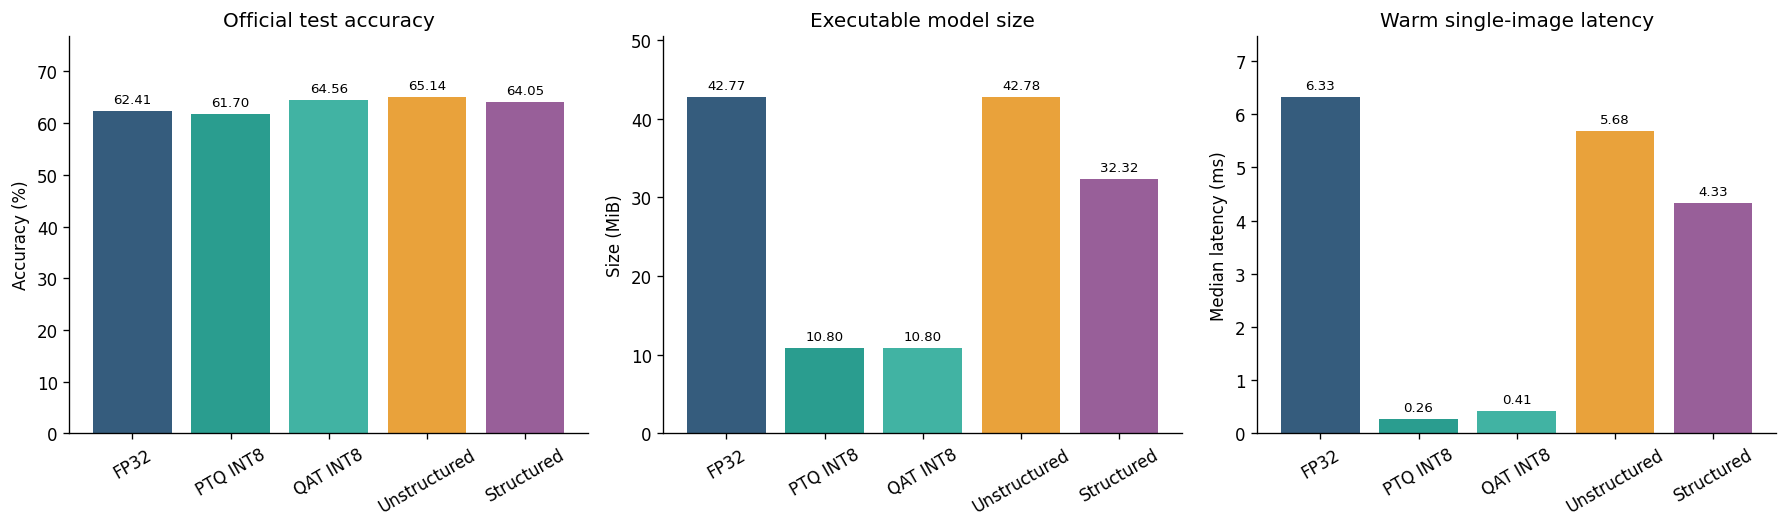

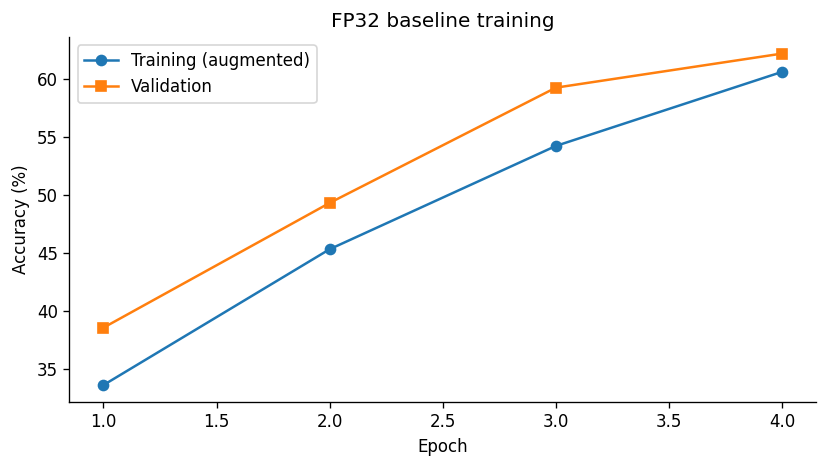

,model,accuracy_pct,checkpoint_mib,latency_p50_ms,accuracy_change_pp,size_reduction_pct,latency_speedup
0,fp32,62.41,42.774,6.330,0.00,0.000,1.000
1,ptq_int8,61.70,10.797,0.261,-0.71,74.758,24.217
2,qat_int8,64.56,10.797,0.415,2.15,74.758,15.270
3,unstructured,65.14,42.783,5.679,2.73,-0.022,1.115
4,structured,64.05,32.316,4.327,1.64,24.448,1.463


In [22]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
labels = ['FP32','PTQ INT8','QAT INT8','Unstructured','Structured']
fig, axes = plt.subplots(1,3,figsize=(15,4.5))
colors=['#355C7D','#2A9D8F','#41B3A3','#E9A23B','#985F99']
for ax, column, title, ylabel in zip(axes,
    ['accuracy_pct','checkpoint_mib','latency_p50_ms'],
    ['Official test accuracy','Executable model size','Warm single-image latency'],
    ['Accuracy (%)','Size (MiB)','Median latency (ms)']):
    bars=ax.bar(labels,benchmark_results[column],color=colors)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.tick_params(axis='x',rotation=30)
    ax.bar_label(bars,fmt='%.2f',padding=3,fontsize=8); ax.margins(y=0.18)
fig.tight_layout(); fig.savefig(ROOT/'results/comparison.png',bbox_inches='tight'); plt.show()

history=pd.read_csv(ROOT/'results/baseline_training.csv')
fig, ax=plt.subplots(figsize=(7,4))
ax.plot(history.epoch,history.train_accuracy_pct,'o-',label='Training (augmented)')
ax.plot(history.epoch,history.val_accuracy_pct,'s-',label='Validation')
ax.set(xlabel='Epoch',ylabel='Accuracy (%)',title='FP32 baseline training'); ax.legend()
fig.tight_layout();fig.savefig(ROOT/'results/training_curve.png',bbox_inches='tight');plt.show()

baseline=benchmark_results.iloc[0]
comparison=benchmark_results[['model','accuracy_pct','checkpoint_mib','latency_p50_ms']].copy()
comparison['accuracy_change_pp']=comparison.accuracy_pct-baseline.accuracy_pct
comparison['size_reduction_pct']=100*(1-comparison.checkpoint_mib/baseline.checkpoint_mib)
comparison['latency_speedup']=baseline.latency_p50_ms/comparison.latency_p50_ms
comparison.to_csv(ROOT/'results/comparison.csv',index=False)
display(comparison.round(3))

## 11. Technical report and reproducible command-line pipeline
The next cell writes a report using actual measured results and produces a README and dependency list. The standalone pipeline runs the same sequence as the notebook. The saved `.pth` files contain retrainable FP32 states with architecture metadata; `.pt` files are the five directly executable deployment checkpoints.

The gzipped unstructured checkpoint is storage compression of the permanent zero-weight state; it must be decompressed before `torch.load`. ONNX models are exported separately for CPU deployment. No GPU, external pruning library or custom native extension is required.

In [23]:
%%writefile scripts/run_all.py
"""One-command reproduction of all training, optimization and deployment experiments."""
from common import *
from train_baseline import run as baseline
from ptq import run as ptq
from qat import run as qat
from prune_unstructured import run as unstructured
from prune_structured import run as structured
from benchmark import run as benchmark
from export_onnx import run as onnx_export

if __name__=='__main__':
    cfg=load_config();setup(cfg['seed'],cfg['threads']);loaders=data(cfg)
    baseline(cfg,loaders);ptq(cfg,loaders);qat(cfg,loaders)
    unstructured(cfg,loaders);structured(cfg,loaders)
    benchmark(cfg,loaders[3]);onnx_export(cfg,loaders[3])


Overwriting scripts/run_all.py


In [24]:
requirements = """torch==2.5.1
torchvision==0.20.1
numpy==2.3.5
pandas
matplotlib
onnx==1.23.2
onnxruntime==1.31.1
nbformat
nbclient
ipykernel
Pillow
"""
(ROOT/'requirements.txt').write_text(requirements)
readme = """# Assignment 3: ResNet-18 quantization and pruning

Student: Ahmed Izaan | Section: A

## Files
- Assignment_3_Solved.ipynb: complete implementation, explanations and executed outputs.
- scripts/: separate baseline, PTQ, calibration, QAT, pruning, inference, benchmarking and ONNX scripts.
- models/: retrainable FP32 states (.pth), five executable TorchScript models (.pt), and compressed unstructured state (.pth.gz).
- onnx/: five deployable ONNX models (INT8 models use Q/DQ graphs).
- results/: full-test summary/predictions CSVs, split indices, training logs, export checks and result figures.
- TECHNICAL_REPORT.md: implementation details, measured results and figures.

## Installation
Use Python 3.12 on x86 CPU/Linux (tested). From the extracted folder:

    python -m pip install torch==2.5.1 torchvision==0.20.1 --index-url https://download.pytorch.org/whl/cpu
    python -m pip install -r requirements.txt

Start Jupyter and open Assignment_3_Solved.ipynb. Run All recreates scripts and results.
Alternatively:

    python scripts/run_all.py

Before running scripts on another computer, set data_dir in config.json to a local writable folder, for example ./data. No CIFAR-10 data is included. The first run downloads it; allow enough disk space and network access.
The notebook sets a default data folder relative to the extracted project. Change config in its setup cell if desired.

## Individual stages
    python scripts/train_baseline.py
    python scripts/ptq.py
    python scripts/qat.py
    python scripts/prune_unstructured.py
    python scripts/prune_structured.py
    python scripts/benchmark.py
    python scripts/export_onnx.py

Run baseline training before optimization. Benchmark/export require all five checkpoints.

## CPU inference
    python scripts/inference.py --model qat_int8 --index 0
    python scripts/inference.py --model structured --image path/to/image.png
    python scripts/onnx_inference.py --model ptq_int8 --index 0

Model choices: fp32, ptq_int8, qat_int8, unstructured, structured.

## Reproduction and interpretation
Fixed seed 42, deterministic PyTorch operations where supported (warn-only for quantized kernels), four CPU threads, no test-set tuning. The run uses 45,000 training examples, 5,000 validation examples and all 10,000 test examples. Calibration uses 1,000 balanced images from training. Four baseline epochs and short recovery/QAT runs are recorded in config.json; increase baseline_epochs for stronger accuracy. Hardware and software affect latency and exact training results.

For the required classroom upload, rename the ZIP to YOUR-ROLL-NUM_A.zip. Roll number was not supplied and is not invented.
"""
(ROOT/'README.md').write_text(readme)
# Build a report without an optional Markdown table dependency.
def markdown_table(df):
    head='| '+' | '.join(map(str,df.columns))+' |\n'
    line='| '+' | '.join(['---']*len(df.columns))+' |\n'
    return head+line+'\n'.join('| '+' | '.join(map(str,row))+' |' for row in df.values.tolist())
report = f"""# Technical report: Assignment 3
Student: Ahmed Izaan | Section: A

## 1. Experimental setup
One quantizable torchvision ResNet-18 is trained from scratch on CIFAR-10, with a ten-class head. The original ImageNet-style stem is retained for CPU feasibility. This aggressively reduces CIFAR spatial resolution and is a limitation; the model is not claimed to be converged.

Training/validation/test: 45,000 / 5,000 / 10,000 images. Split is stratified and recorded in results/data_split.npz. Seed: 42. Batch size: 128. CPU threads: 4. Baseline epochs: {config['baseline_epochs']}; QAT epochs: {config['qat_epochs']}; final pruning fine-tuning epochs per method: {config['finetune_epochs']}. SGD uses momentum 0.9 and weight decay 0.0005, with cosine learning-rate decay. Baseline LR: 0.05; QAT LR: 0.001; final unstructured LR: 0.001; structured LR: 0.002. Best FP32 epoch is selected by validation accuracy. No test examples are used in training, calibration or model selection.

## 2. Question 1 implementation
Compatible Conv-BN-ReLU groups are fused using torchvision's quantizable ResNet fusion method. PTQ inserts FBGEMM observers, calibrates on 1,000 balanced non-augmented training images and converts to true INT8 convolution/linear operations. QAT reloads exactly the same FP32 checkpoint, fuses in QAT mode, inserts fake quantizers, fine-tunes with frozen BN statistics and freezes observers halfway through the last epoch. Conversion removes training-only fake quantization and deploys real INT8 kernels.

## 3. Question 2 implementation
Unstructured pruning applies global L1 magnitude masks to all Conv2d/Linear weights. Three iterations each prune 20% of the currently surviving weights, yielding approximately 48.8% sparsity. Each iteration has one short recovery epoch on 5,000 training images. A final recovery epoch uses the full training split. Masks remain active during training and are folded permanently only afterward. A gzip checkpoint improves stored sparse-weight compressibility, but dense execution does not skip zero weights.

Structured pruning physically removes the lowest-magnitude 25% of conv1 output channels inside each of the eight residual BasicBlocks. Matching bn1 features and conv2 input channels are removed. Block output widths and projection paths stay valid, so residual additions require no arbitrary slicing. Checkpoints include the reconstructed channel widths and are successfully reloaded independently. The structured network has fewer real parameters, rather than only extra zero weights. Validation accuracy before and after recovery is recorded in results/structured_recovery.json.

## 4. Measured full-test results
{markdown_table(benchmark_results.round(4))}

## 5. Relative comparison
{markdown_table(comparison.round(4))}

All checkpoints are reloaded from disk before benchmarking. Accuracy covers every official test image. Twenty synthetic warm-up calls precede 100 single-image latency measurements. Batch throughput times only model forward calls over the full test dataset. Preprocessing, loading and CSV writing are excluded. Batch timings are repeated for each prediction row for auditability; the per-image amortized time is not a measured batch-size-one latency.

## 6. ONNX verification
{markdown_table(onnx_results.round(6))}

ONNX graphs pass structural checking and actual ONNX Runtime CPU execution. Logit error is checked on 32 images, and ONNX test accuracy and prediction agreement are measured on all 10,000 test images. Native and ONNX outputs are compared against the same optimized model, not an unrelated FP32 reference. Q/DQ nodes are checked in the INT8 exports. Quantized backend rounding accumulates across layers. INT8 logit error is checked against three final output quantization steps, and full-test agreement is reported explicitly. These exports are not claimed to be numerically identical to native INT8 inference.

## 7. Figures / captured notebook results
![Measured comparison](results/comparison.png)
![Executed training curve](results/training_curve.png)

These figures reproduce the notebook outputs directly from measured experimental data. The notebook also displays the complete benchmark table, channel reconstruction table, pruning iterations and export verification results.

## 8. Limitations and interpretation
Only a short CPU training schedule is executed. Accuracy should be interpreted alongside the stem choice, training curve and small fine-tuning budget. More epochs and a CIFAR-adapted stem are possible follow-up experiments. QAT and pruning receive extra training, so a matched-training FP32 control would be required for causal claims about accuracy improvements. Four-thread CPU latency is hardware-specific. Dense unstructured pruning does not guarantee smaller raw tensors or faster kernels; the report distinguishes gzip storage compression from executable model size. Structured pruning is restricted to internal residual-block channels to preserve network dependencies. A single 100-call latency sample is an illustrative measurement rather than a rigorous multi-process performance study.

## 9. References
- Assignment 3, Edge Computing & Intelligent Systems (provided PDF).
- PyTorch quantization API: https://docs.pytorch.org/docs/stable/quantization-support.html
- PyTorch pruning tutorial: https://docs.pytorch.org/tutorials/intermediate/pruning_tutorial.html
- torchvision quantizable ResNet implementation (v0.20.1): https://github.com/pytorch/vision/blob/v0.20.1/torchvision/models/quantization/resnet.py
- CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
"""
(ROOT/'TECHNICAL_REPORT.md').write_text(report)
print('README, dependency list and measured technical report written.')
print('Five native executable models:', [p.name for p in sorted((ROOT/'models').glob('*.pt'))])
print('Five ONNX models:', [p.name for p in sorted((ROOT/'onnx').glob('*.onnx'))])

README, dependency list and measured technical report written.
Five native executable models: ['fp32.pt', 'ptq_int8.pt', 'qat_int8.pt', 'structured.pt', 'unstructured.pt']
Five ONNX models: ['fp32.onnx', 'ptq_int8.onnx', 'qat_int8.onnx', 'structured.onnx', 'unstructured.onnx']


## 12. Final verification checklist
The final cell checks saved models, result coverage and ONNX verification. The execution counts and displayed outputs are preserved in this notebook. The accompanying ZIP contains the required scripts, trained checkpoints, CSVs, documentation and ONNX files. Rename the ZIP with your actual roll number before submitting.

In [25]:
for name in NAMES:
    assert (ROOT/'models'/f'{name}.pt').is_file()
    assert (ROOT/'onnx'/f'{name}.onnx').is_file()
assert len(predictions)==50000
assert benchmark_results.test_images.eq(10000).all()
assert len(onnx_results)==5
print('PASS: all five models load, all 50,000 model/image predictions exist, and all five ONNX exports execute.')
print('Questions 1 and 2 completed. Review the reported limitations and viva explanations before submission.')

PASS: all five models load, all 50,000 model/image predictions exist, and all five ONNX exports execute.
Questions 1 and 2 completed. Review the reported limitations and viva explanations before submission.
